In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
data = sc.read_h5ad("../experiments/experiment4_predict_perturb_add_test_data/interception_predict_to_gene1_plus_gene2.h5ad")

X = data.X
# print(X)
# X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# print(X.size)
# X = X.astype(np.float32)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print(total)
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)

print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)

(152, 33694)
5121488
5121488
min: 0.0
max: 9.240264
mean: 0.08825994
below 0: 0
below 0: 0.0
below 0.1: 4290529
below 0.1: 0.8377504740809703
equals 0: 2034073
equals 0: 0.3971644568922157
below 18: 5121488
below 18: 1.0
nan: 0


0.9813781041881131 0.9910004421608252
4.8650475 5.0324745


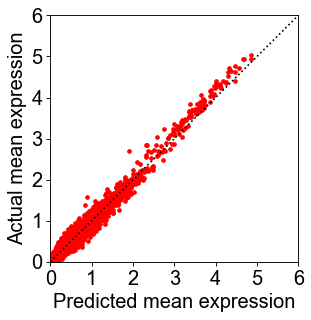

In [3]:
r_all = []
pearsonr_all = []

predict_data =  sc.read_h5ad("../experiments/experiment4_predict_perturb_add_test_data/interception_predict_to_gene1_plus_gene2.h5ad")
real_data = sc.read_h5ad("../../input/test_data.h5ad")

r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print(r2, pearsonr)

# r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
# print(r2_new, pearson_new)
r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

# pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
# pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))

fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
             s=10,
             c='red'
           )
ax.set_ylim(bottom=0)
ax.set_xlim(left=0)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xticks(np.arange(0, limit + 1, 1))
plt.yticks(np.arange(0, limit + 1, 1)) 
plt.xlabel("Predicted mean expression")
plt.ylabel("Actual mean expression")
fig.savefig(os.path.join(f"prediction_gene1_plus_gene2_exp4.pdf"), bbox_inches="tight")


0.9828381951945183 0.9918379379218362
5.033827 5.0324745


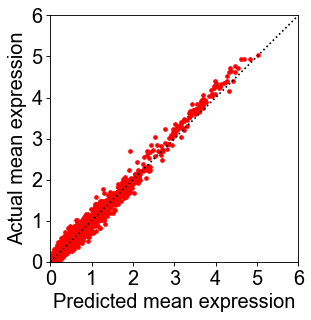

In [4]:
r_all = []
pearsonr_all = []

predict_data = sc.read_h5ad("../experiments/experiment4_predict_perturb_add_test_data_using_combine_data/interception_predict_to_gene1_plus_gene2_v2.h5ad")
real_data = sc.read_h5ad("../../input/test_data.h5ad")

r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print(r2, pearsonr)

# r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
# print(r2_new, pearson_new)
r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

# pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
# pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))

fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
             s=10,
             c='red'
           )
ax.set_ylim(bottom=0)
ax.set_xlim(left=0)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xticks(np.arange(0, limit + 1, 1))
plt.yticks(np.arange(0, limit + 1, 1)) 
plt.xlabel("Predicted mean expression")
plt.ylabel("Actual mean expression")
fig.savefig(os.path.join(f"prediction_gene_add_test_data_using_combine_data.pdf"), bbox_inches="tight")

AnnData object with n_obs × n_vars = 152 × 33694
AnnData object with n_obs × n_vars = 152 × 33694
    obs: 'Group'
    var: 'gene_ids'
    uns: 'log1p'
0.9823610051395008 0.9914848696315638
4.897903 5.0324745


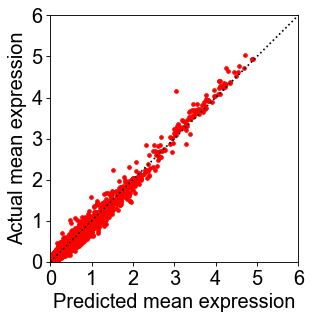

In [5]:
r_all = []
pearsonr_all = []

predict_data = sc.read_h5ad("../experiments/experiment4_predict_perturb_no_test_data/interception_predict_to_gene1_plus_gene2.h5ad")
print(predict_data)
real_data = sc.read_h5ad("../../input/test_data.h5ad")
print(real_data)
r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print(r2, pearsonr)

# r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
# print(r2_new, pearson_new)
r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

# pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
# pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))

fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
             s=10,
             c='red'
           )
ax.set_ylim(bottom=0)
ax.set_xlim(left=0)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xticks(np.arange(0, limit + 1, 1))
plt.yticks(np.arange(0, limit + 1, 1)) 
plt.xlabel("Predicted mean expression")
plt.ylabel("Actual mean expression")
fig.savefig(os.path.join(f"prediction_gene_no_add_test_data.pdf"), bbox_inches="tight")